In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_excel(r"D:\مشاريع\Python-Sales-Analysis\data\Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df["InvoiceNo"].astype(str).str.startswith("C").value_counts()

InvoiceNo
False    532621
True       9288
Name: count, dtype: int64

In [10]:
sales_df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [11]:
sales_df.shape

(532621, 8)

In [12]:
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

In [13]:
sales_df[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [14]:
sales_df[["Quantity", "UnitPrice", "Revenue"]].describe()

,Quantity,UnitPrice,Revenue
count,532621.000000,532621.000000,532621.000000
mean,10.239972,3.847621,19.985244
std,159.593551,41.758023,270.574241
min,-9600.000000,-11062.060000,-11062.060000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.080000,9.900000
75%,10.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


In [15]:
(sales_df["Quantity"] < 0).sum()

np.int64(1336)

In [16]:
(sales_df["UnitPrice"] < 0).sum()

np.int64(2)

In [17]:
sales_df[sales_df["Quantity"] < 0][
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]
].head(20)

,InvoiceNo,Description,Quantity,UnitPrice,Revenue
2406,536589,NaN,-10,0.0,-0.0
4347,536764,NaN,-38,0.0,-0.0
7188,536996,NaN,-20,0.0,-0.0
7189,536997,NaN,-20,0.0,-0.0
7190,536998,NaN,-6,0.0,-0.0
7192,537000,NaN,-22,0.0,-0.0
7193,537001,NaN,-6,0.0,-0.0
7195,537003,NaN,-2,0.0,-0.0
7196,537004,NaN,-30,0.0,-0.0
7197,537005,NaN,-70,0.0,-0.0


In [18]:
sales_df[sales_df["UnitPrice"] < 0][
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue
299983,A563186,B,Adjust bad debt,1,-11062.06,-11062.06
299984,A563187,B,Adjust bad debt,1,-11062.06,-11062.06


In [19]:
sales_df = sales_df[sales_df["UnitPrice"] > 0].copy()

In [20]:
print(sales_df.shape)
print("Negative UnitPrice:", (sales_df["UnitPrice"] < 0).sum())

(530104, 9)
Negative UnitPrice: 0


In [21]:
negative_qty = sales_df[sales_df["Quantity"] < 0]

negative_qty[
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
].head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue


In [22]:
print("Negative Quantity:", (sales_df["Quantity"] < 0).sum())

Negative Quantity: 0


In [23]:
sales_df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,Revenue
count,530104.000000,530104,530104.000000,397884.000000,530104.000000
mean,10.542037,2011-07-04 20:16:05.225087744,3.907625,15294.423453,20.121871
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,1.000000,2011-03-28 12:22:00,1.250000,13969.000000,3.750000
50%,3.000000,2011-07-20 12:58:00,2.080000,15159.000000,9.900000
75%,10.000000,2011-10-19 12:39:00,4.130000,16795.000000,17.700000
max,80995.000000,2011-12-09 12:50:00,13541.330000,18287.000000,168469.600000
std,155.524124,NaN,35.915681,1713.141560,270.356743


In [24]:
sales_df[["Quantity", "UnitPrice", "Revenue"]].describe()

,Quantity,UnitPrice,Revenue
count,530104.000000,530104.000000,530104.000000
mean,10.542037,3.907625,20.121871
std,155.524124,35.915681,270.356743
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.080000,9.900000
75%,10.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


In [25]:
print("Total Revenue:", sales_df["Revenue"].sum())
print("Total Orders:", sales_df["InvoiceNo"].nunique())
print("Total Products:", sales_df["StockCode"].nunique())
print("Total Countries:", sales_df["Country"].nunique())

Total Revenue: 10666684.544
Total Orders: 19960
Total Products: 3922
Total Countries: 38


In [26]:
top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: Revenue, dtype: float64

In [27]:
sales_df[sales_df["Description"].str.contains(
    "POSTAGE|MANUAL|DOTCOM", case=False, na=False
)]["Description"].value_counts()

Description
POSTAGE                                1126
DOTCOM POSTAGE                          706
Manual                                  322
Dotcomgiftshop Gift Voucher £20.00        9
Dotcomgiftshop Gift Voucher £10.00        8
Dotcomgiftshop Gift Voucher £30.00        7
MUG , DOTCOMGIFTSHOP.COM                  5
Dotcomgiftshop Gift Voucher £50.00        4
Dotcomgiftshop Gift Voucher £40.00        3
DOTCOMGIFTSHOP TEA TOWEL                  2
Dotcomgiftshop Gift Voucher £100.00       1
Name: count, dtype: int64

In [28]:
product_sales = sales_df[
    ~sales_df["Description"].isin(["POSTAGE", "DOTCOM POSTAGE", "Manual"])
].copy()

In [29]:
top_products = (
    product_sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66964.99
PAPER CHAIN KIT 50'S CHRISTMAS         64952.29
ASSORTED COLOUR BIRD ORNAMENT          59094.93
CHILLI LIGHTS                          54117.76
Name: Revenue, dtype: float64

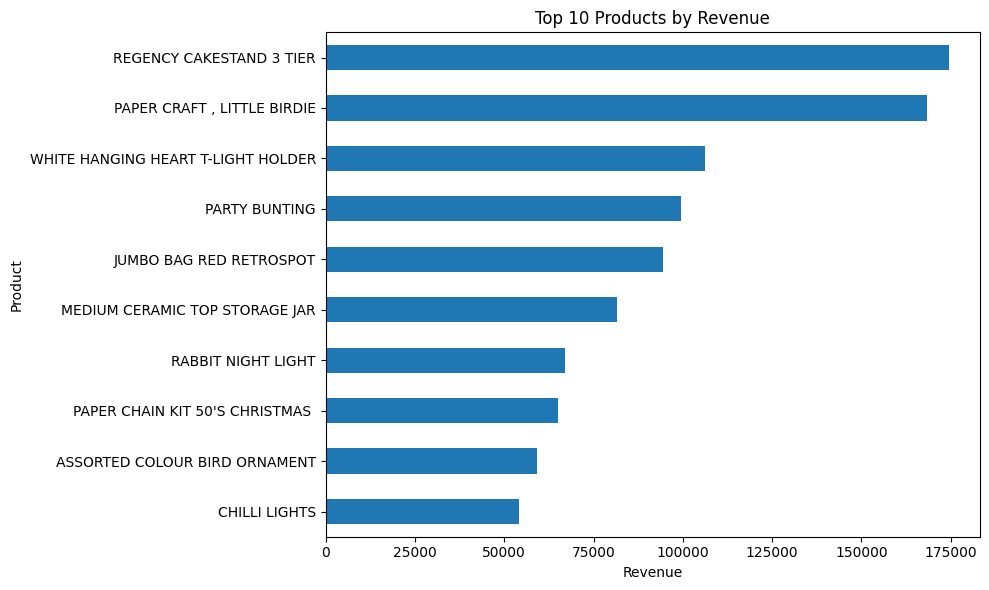

In [30]:
top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Products by Revenue"
)

plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [31]:
country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64

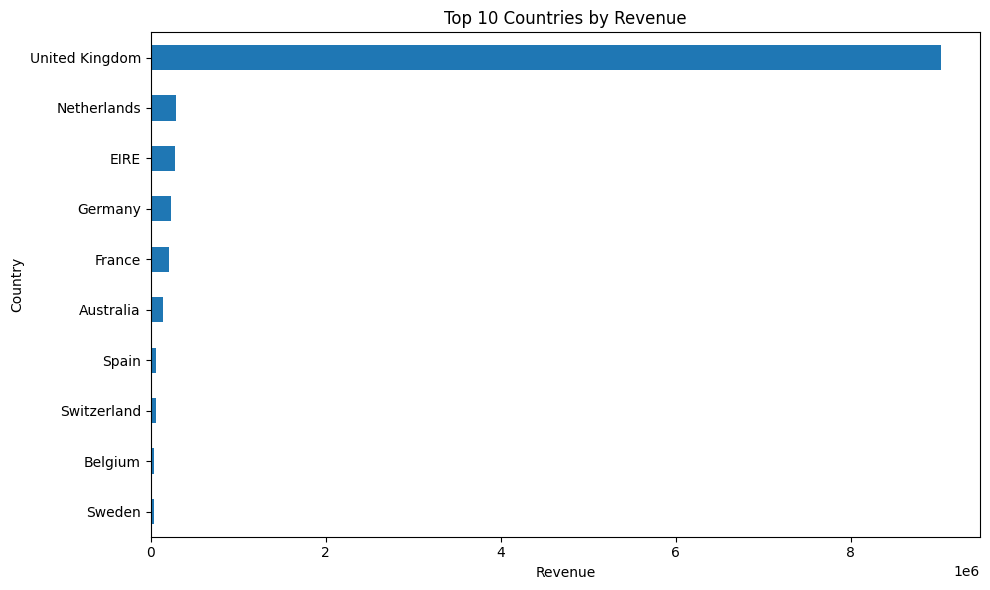

In [32]:
country_sales.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Countries by Revenue"
)

plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [33]:
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

In [34]:
monthly_sales = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
)

monthly_sales

Month
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64

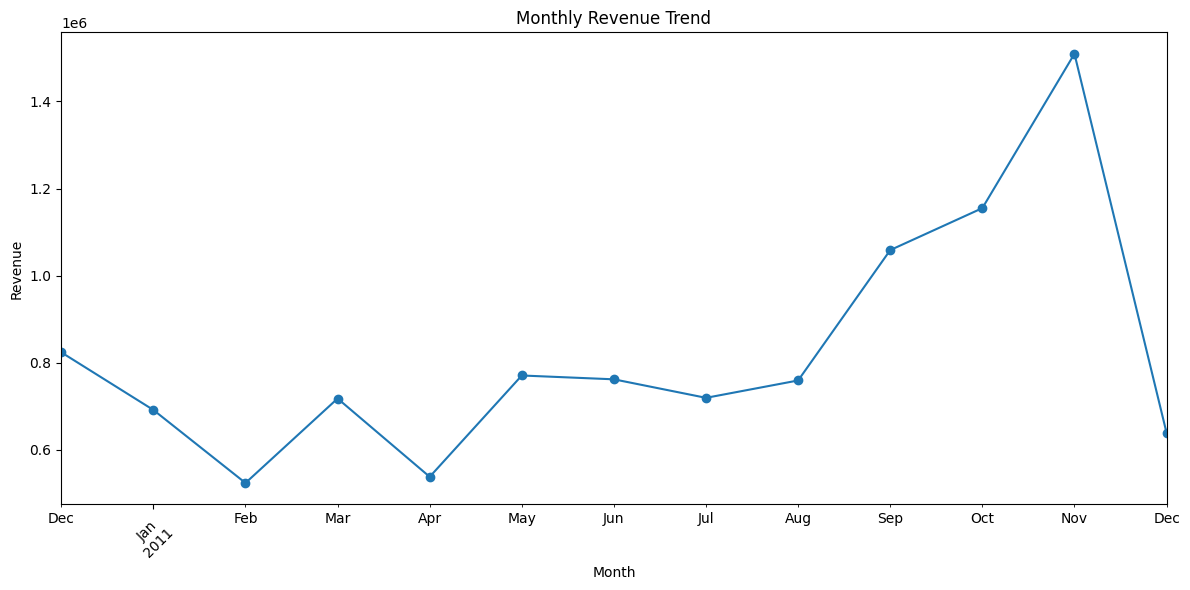

In [35]:
monthly_sales.plot(
    figsize=(12, 6),
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
customer_sales = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

customer_sales

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Revenue, dtype: float64

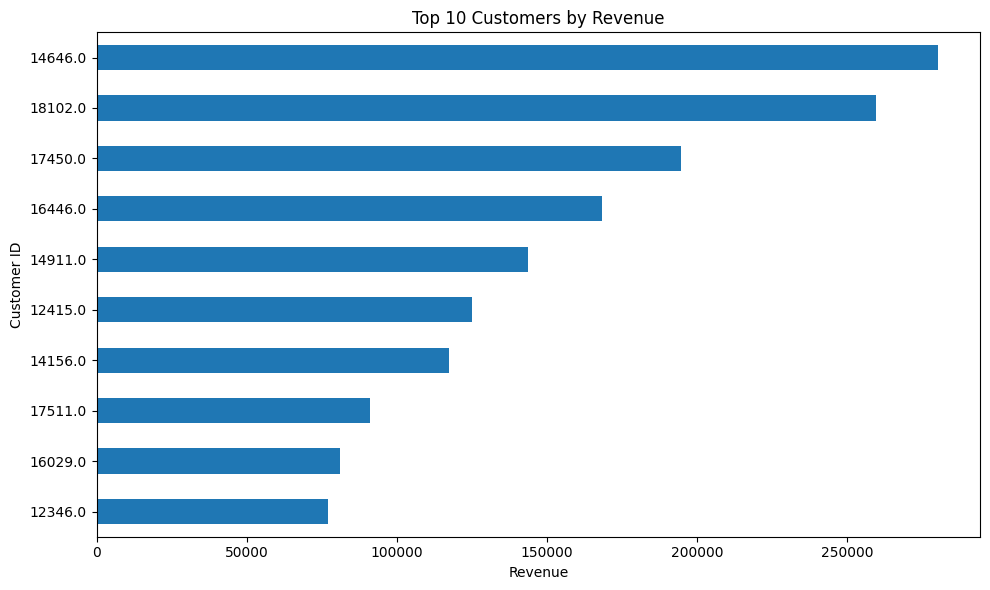

In [37]:
customer_sales.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Customers by Revenue"
)

plt.xlabel("Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

## Key Insights

* The dataset contains over 530,000 valid sales transactions after data cleaning.
* Total revenue generated from the analyzed sales is approximately **£10.67 million**.
* The **United Kingdom** generated the highest revenue among all countries, with approximately **£9.03 million**.
* **November 2011** recorded the highest monthly revenue, reaching approximately **£1.51 million**.
* **REGENCY CAKESTAND 3 TIER** was the highest-revenue product, generating approximately **£174.5K**.
* Customer **14646** generated the highest revenue among customers with available Customer IDs, with approximately **£280.2K**.
* The analysis shows noticeable variation in revenue across countries, products, customers, and months.


## Conclusion

This project analyzed an online retail sales dataset using Python and Pandas.

The analysis included data cleaning, revenue calculation, and exploratory data analysis to identify patterns in sales performance. Different aspects of the data were examined, including products, countries, monthly revenue, and customers.

The results provide a clear overview of sales performance and highlight the products, countries, months, and customers that contributed most to the overall revenue.
